# 03 · Synthetic event generation — Gaussian copula with `pyhydra`

Navas et al. (2024) describe every rainfall event by four parameters at each of the 17 gauges — **Pmax**, **Pmed**, **Duration** and hyetograph **Type** — plus the 16 inter-gauge time **lags**. A Normal (Gaussian) copula with BIC-selected marginals is fitted to that joint table, and about **1 million** synthetic events are drawn from it. Figures 6 and 7 of the paper show the result for gauge **P_27**.

This notebook runs that step with `pyhydra.climate.spatial_analysis.copulas.FloodEventCopula`, which uses OpenTURNS internally:

* **Continuous marginals.** Pmax, Pmed, Duration and the lags are continuous. Their BIC search is restricted to physically meaningful families: positive families for rainfall and duration, symmetric ones for the lags.
* **Zero-inflated marginals.** Pmax and Pmed are *zero-inflated*: a gauge that stays dry during an event records exactly 0, which is about 35–40 % of the entries. Each one gets a mixture marginal `p0·δ0 + (1 − p0)·F+`, so the dry share is reproduced exactly instead of being smeared into a heavy-tailed continuous fit.
* **Discrete marginals.** Type is discrete and gets an empirical marginal.

**Data provenance — read before interpreting the results.** The 1,761 historical events that Navas et al. (2024) fitted the copula to are third-party gauge data (CHT and MAPA networks) and are **not redistributed** with this repository. The notebook therefore uses, as its calibration set, the archived 10,000-event sample of the original synthetic catalogue (`events/events_synthetic_sample.csv`). It then checks that the regenerated catalogue reproduces that sample's marginals and dependence structure. If you hold the historical event table, save it as `events/events_historical.csv` with the same column layout and the next cell will fit it instead.


In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

_cwd = Path.cwd()
_candidates = [Path('/workspace'), _cwd, *_cwd.parents]
REPO_ROOT = next(
    (p for p in _candidates if (p / 'notebooks').exists() or (p / 'pyhydra').exists()),
    _cwd,
)
DATA_DIR  = Path(os.environ.get('HYDRA_DATA_DIR', str(REPO_ROOT / 'data')))
DATA_ROOT = DATA_DIR / 'pilot_cases' / 'm30_manzanares'

EVENTS_DIR   = DATA_ROOT / 'events'
RESULTS_DIR  = DATA_ROOT / 'results'
STATIONS_DIR = DATA_ROOT / 'stations'

print('DATA_ROOT:', DATA_ROOT)

T_VALS   = [2, 5, 10, 20, 50, 100, 500]
N_STAT   = 17
LAM      = 5.17    # Poisson rate (events/year)
XS_PT    = 6262    # Toledo Bridge cross-section
XS_R9    = 4112    # Weir No.9 cross-section

from pyhydra.climate.spatial_analysis.copulas import FloodEventCopula

N_SYNTH   = 100_000   # synthetic events drawn here (the paper draws ~1e6)
SEED      = 2024


DATA_ROOT: data/pilot_cases/m30_manzanares


In [2]:
historical_path = EVENTS_DIR / 'events_historical.csv'
if historical_path.exists():
    calib = pd.read_csv(historical_path, index_col=0)
    calib_label = 'historical events (project data)'
else:
    calib = pd.read_csv(EVENTS_DIR / 'events_synthetic_sample.csv', index_col=0)
    calib_label = 'archived synthetic sample (proxy)'
selected = pd.read_csv(EVENTS_DIR / 'events_selected.csv', index_col=0)

discrete_vars   = [c for c in calib.columns if c.startswith('Tipo')]
continuous_vars = [c for c in calib.columns if c not in discrete_vars]
zero_inflated   = [c for c in continuous_vars if c.startswith(('Pmax', 'Pmed'))]

POSITIVE = ['Exponential', 'Gamma', 'LogNormal', 'WeibullMin']
SYMMETRIC = ['Normal', 'TruncatedNormal', 'Beta']
families = {c: (SYMMETRIC if c.startswith('lags') else POSITIVE) for c in continuous_vars}

print(f'Calibration set: {calib_label} — {len(calib):,} events × {calib.shape[1]} variables')
print(f'  continuous: {len(continuous_vars)}  (of which zero-inflated: {len(zero_inflated)})')
print(f'  discrete:   {len(discrete_vars)}')
print(f'  share of dry entries (Pmax = 0) per gauge: '
      f'{(calib[[c for c in zero_inflated if c.startswith("Pmax")]] == 0).mean().min():.2f}–'
      f'{(calib[[c for c in zero_inflated if c.startswith("Pmax")]] == 0).mean().max():.2f}')


Calibration set: archived synthetic sample (proxy) — 10,000 events × 84 variables
  continuous: 67  (of which zero-inflated: 34)
  discrete:   17
  share of dry entries (Pmax = 0) per gauge: 0.31–0.48


In [3]:
import time

t0 = time.time()
copula = FloodEventCopula(
    continuous_vars=continuous_vars,
    discrete_vars=discrete_vars,
    families=families,
    zero_inflated_vars=zero_inflated,
    random_state=SEED,
    verbose=False,
).fit(calib)
t_fit = time.time() - t0

t0 = time.time()
synthetic = copula.sample(N_SYNTH)
t_sample = time.time() - t0

print(f'Fitted {len(copula._all_vars)}-dimensional Normal copula in {t_fit:.1f} s')
print(f'Sampled {len(synthetic):,} synthetic events in {t_sample:.1f} s')
print()
print('Selected marginal families (continuous variables):')
print(pd.Series({v: d.getName() for v, (d, _) in copula._marginals.items()
                 if v in continuous_vars}).value_counts().to_string())

# Keep the regenerated catalogue for the MaxDiss step (notebook 04).
np.savez_compressed(EVENTS_DIR / 'events_synthetic_pyhydra.npz',
                    values=synthetic[calib.columns].to_numpy(np.float32),
                    columns=np.array(calib.columns, dtype=str))


WRN - class UserDefinedFactory is deprecated in favor of FiniteDiscreteDistributionFactory


Fitted 84-dimensional Normal copula in 19.2 s
Sampled 100,000 synthetic events in 7.3 s

Selected marginal families (continuous variables):
Exponential    24
WeibullMin     22
Normal         16
Gamma           3
LogNormal       2


## Validation — does the regenerated catalogue reproduce the calibration set?

Marginals are compared at gauge P_27 (the gauge shown in the paper). Dependence is compared over **all** variable pairs through the Spearman rank-correlation matrix, which is what the Normal copula is meant to carry.

In [4]:
rows = []
for col, label in [('Pmax1', 'Pmax (mm)'), ('Pmed1', 'Pmed (mm)'),
                   ('Duracion1', 'Duration (h)'), ('Tipo1', 'Type')]:
    for name, df in [(calib_label.split(' (')[0], calib), ('pyhydra copula', synthetic)]:
        v = df[col]
        rows.append({'variable': label, 'set': name,
                     'dry share': (v == 0).mean(),
                     'median': v.median(), 'q95': v.quantile(0.95),
                     'q99': v.quantile(0.99)})
print('Gauge P_27 — marginal summary')
print(pd.DataFrame(rows).set_index(['variable', 'set']).round(3).to_string())

rho_cal = calib.corr('spearman').to_numpy()
rho_syn = synthetic[calib.columns].corr('spearman').to_numpy()
iu = np.triu_indices_from(rho_cal, 1)
err = np.abs(rho_cal[iu] - rho_syn[iu])
print()
print(f'Spearman matrix over {len(iu[0]):,} variable pairs: '
      f'mean |Δρ| = {err.mean():.3f}, 95th pct |Δρ| = {np.quantile(err, 0.95):.3f}, '
      f'max |Δρ| = {err.max():.3f}, corr(ρ_cal, ρ_syn) = {np.corrcoef(rho_cal[iu], rho_syn[iu])[0, 1]:.3f}')


Gauge P_27 — marginal summary
                                        dry share  median     q95     q99
variable     set                                                         
Pmax (mm)    archived synthetic sample      0.343   1.211  10.508  13.632
             pyhydra copula                 0.342   1.245  10.975  17.755
Pmed (mm)    archived synthetic sample      0.343   0.162   1.365   2.027
             pyhydra copula                 0.342   0.167   1.376   2.180
Duration (h) archived synthetic sample      0.000  14.463  59.089  90.677
             pyhydra copula                 0.000  14.348  59.109  90.884
Type         archived synthetic sample      0.041   6.000  23.000  24.000
             pyhydra copula                 0.040   6.000  23.000  24.000



Spearman matrix over 3,486 variable pairs: mean |Δρ| = 0.011, 95th pct |Δρ| = 0.047, max |Δρ| = 0.068, corr(ρ_cal, ρ_syn) = 0.999


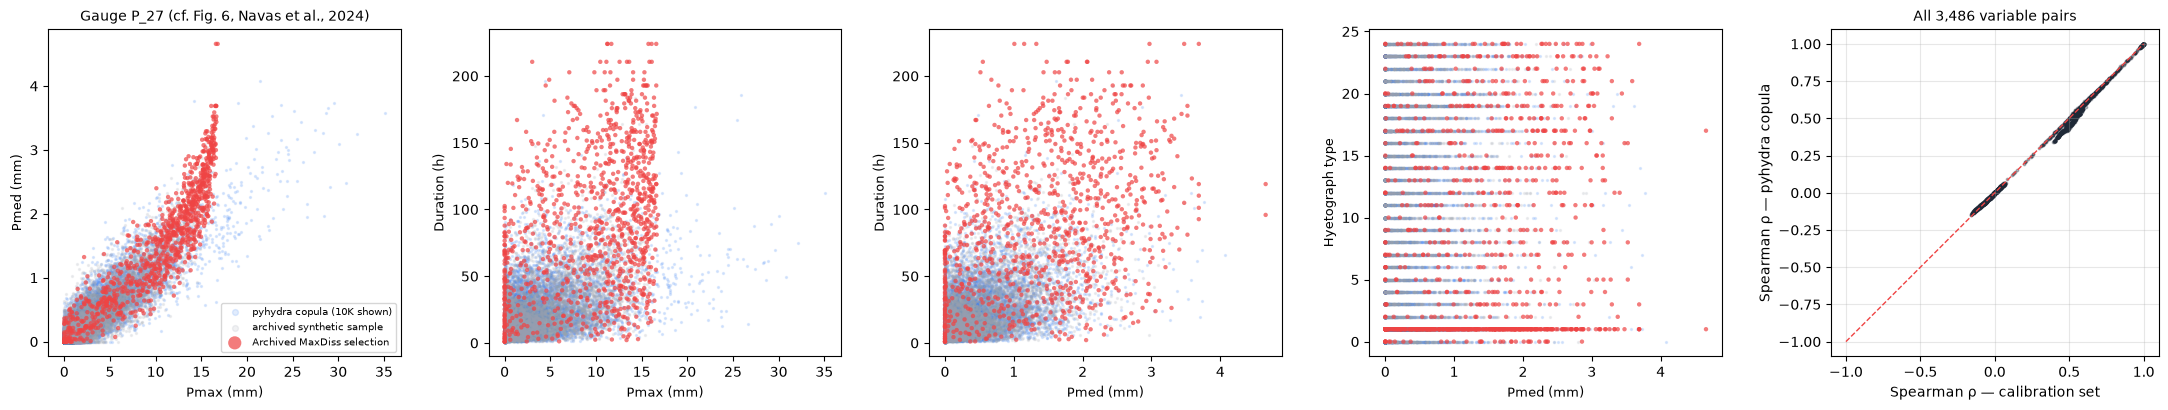

In [5]:
fig, axes = plt.subplots(1, 5, figsize=(22, 4.2),
                         gridspec_kw={'width_ratios': [1, 1, 1, 1, 1.05]})
pairs = [
    ('Pmax1', 'Pmed1',     'Pmax (mm)', 'Pmed (mm)'),
    ('Pmax1', 'Duracion1', 'Pmax (mm)', 'Duration (h)'),
    ('Pmed1', 'Duracion1', 'Pmed (mm)', 'Duration (h)'),
    ('Pmed1', 'Tipo1',     'Pmed (mm)', 'Hyetograph type'),
]
show = synthetic.sample(10_000, random_state=SEED)
for ax, (xc, yc, xl, yl) in zip(axes, pairs):
    ax.scatter(show[xc], show[yc], s=2, alpha=0.15, c='#3b82f6', rasterized=True,
               label='pyhydra copula (10K shown)')
    ax.scatter(calib[xc], calib[yc], s=2, alpha=0.15, c='#9ca3af', rasterized=True,
               label=calib_label.split(' (')[0])
    ax.scatter(selected[xc], selected[yc], s=10, alpha=0.7, c='#ef4444',
               edgecolors='none', label='Archived MaxDiss selection', zorder=3)
    ax.set_xlabel(xl, fontsize=9); ax.set_ylabel(yl, fontsize=9)
axes[0].legend(fontsize=7, markerscale=3)
axes[0].set_title('Gauge P_27 (cf. Fig. 6, Navas et al., 2024)', fontsize=10)

ax = axes[4]
ax.scatter(rho_cal[iu], rho_syn[iu], s=3, alpha=0.3, c='#1f2937', rasterized=True)
ax.plot([-1, 1], [-1, 1], '--', c='#ef4444', lw=1)
ax.set_xlabel('Spearman ρ — calibration set'); ax.set_ylabel('Spearman ρ — pyhydra copula')
ax.set_title(f'All {len(iu[0]):,} variable pairs', fontsize=10)
ax.set_aspect('equal'); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()


## What this step reproduces, and what it does not

* **Reproduced.** The regenerated catalogue matches the calibration set's dry-gauge shares and bulk marginals. It also matches the full 84-variable rank-dependence structure, including the near-perfect correlation of event duration across gauges and the weak structure of the inter-gauge lags. This is the property the downstream MaxDiss and hydrological steps rely on.
* **Not reproduced.**
  - The calibration set here is a *proxy*, a sample of the paper's own synthetic catalogue. Agreement with it validates the implementation, not the paper's fit to the historical record.
  - The extreme upper quantiles (above about q99) of zero-inflated rainfall are sensitive to the tail of the selected positive family and should not be over-interpreted.
  - Hydrological (HEC-HMS) and hydraulic (HEC-RAS) responses are not computed in this repository; see notebooks 05–06.